## Transformer-only Model

The Transformer-only model processes normalized input series through patch embedding and Transformer encoder layers to capture temporal relationships. The resulting token representations are mean-pooled and passed to a multi-label classification head.

The architecture is based on the original Transformer proposed by Vaswani et al. (2017), incorporating time-series patching as described by Nie et al. (2022).


**References:**

Nie, Y., Nguyen, N.H., Sinthong, P., Kalagnanam, J., 2023. A time series is worth 64 words: Long-term forecasting with transformers, in: International Conference on Learning Representations (ICLR 2023). https://openreview.net/forum?id=Jbdc0vTOcol.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A.N., Kaiser, Ł., Polosukhin, I., 2017. Attention is all you need, in: Advances in Neural Information Processing Systems, vol. 30. Curran Associates, Inc., pp. 5998–6008. https://proceedings.neurips.cc/paper/2017/hash/3f5ee243547dee91fbd053c1c4a845aa-Abstract.html.

## 1. Libraries and Dependencies

In [1]:
import json
import math
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, Subset, DataLoader
from sklearn.metrics import (f1_score, accuracy_score, hamming_loss,
                             label_ranking_loss, roc_auc_score)
import matplotlib.pyplot as plt

## 2. Model and Training Configuration

In [ ]:
# Dataset path
DATA_DIR = Path("synthetic_dataset")

# Random seeds
SEEDS = [0, 1, 2, 3, 4]

# Data loading
BATCH_SIZE = 32

# Patch segmentation
PATCH_SIZE = 8
D_MODEL = 128

# Transformer encoder
N_HEADS = 8
FF_DIM = 512
N_TRANSFORMER_LAYERS = 4
DROPOUT = 0.1

# Classification head
N_LABELS = 4

# Optimization
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
N_EPOCHS = 30

# Experiment identity and output paths
ARCH_NAME = "transformer_only"
PRED_DIR = DATA_DIR / "predictions"
PRED_DIR.mkdir(exist_ok=True)

def checkpoint_path(seed):
    return DATA_DIR / f"best_{ARCH_NAME}_seed{seed}.pt"

# Computing device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


## 3. Dataset Loading

In [3]:
class CyclesDataset(Dataset):
    """Load synthetic sedimentary series and multi-label targets from NPZ
    and JSON files, with metadata aligned by sample index.
    """

    def __init__(self, npz_path, json_path):
        npz_path = Path(npz_path)
        json_path = Path(json_path)

        if not npz_path.exists():
            raise FileNotFoundError(f".npz file not found: {npz_path}")
        if not json_path.exists():
            raise FileNotFoundError(f".json file not found: {json_path}")

        npz_data = np.load(npz_path, allow_pickle=True)

        self.signals = npz_data["signals"]
        self.depths = npz_data["depths"]
        self.labels = npz_data["labels"]
        self.label_names = list(npz_data["label_names"])

        with open(json_path, "r", encoding="utf-8") as f:
            self.metadata = json.load(f)

        n_signals = self.signals.shape[0]
        n_meta = len(self.metadata)
        assert n_signals == n_meta, (
            f"Mismatch between .npz ({n_signals} series) and .json ({n_meta} entries). "
        )

    def __len__(self):
        return self.signals.shape[0]

    def __getitem__(self, idx: int):
        signal = torch.from_numpy(self.signals[idx]).float()
        depth = torch.from_numpy(self.depths[idx]).float()
        label = torch.from_numpy(self.labels[idx]).float()
        meta = self.metadata[idx]

        return {
            "signal": signal,
            "depth": depth,
            "label": label,
            "metadata": meta,
        }

## 4. Dataset Initialization

In [4]:
# Load the synthetic dataset and verify its size and label order.
ds = CyclesDataset(
    npz_path=DATA_DIR / "synthetic_cyclostratigraphy_dataset.npz",
    json_path=DATA_DIR / "metadata.json",
)
print(f"Total series: {len(ds)}")
print(f"Cycles (Label order): {ds.label_names}")

Total series: 25760
Cycles (Label order): [np.str_('precession'), np.str_('obliquity'), np.str_('E1'), np.str_('E2')]


## 5. Dataset Splitting

In [5]:
def make_splits_from_metadata(dataset):
    """Create training, validation, and test subsets using metadata-defined splits."""
    split_idx = {"train": [], "val": [], "test": []}
    for i, meta in enumerate(dataset.metadata):
        split_idx[meta["split"]].append(i)

    train_set = Subset(dataset, split_idx["train"])
    val_set = Subset(dataset, split_idx["val"])
    test_set = Subset(dataset, split_idx["test"])

    return train_set, val_set, test_set

In [6]:
# Apply the predefined dataset splits and display sample counts.
train_set, val_set, test_set = make_splits_from_metadata(ds)
print(f"Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

Train: 18044 | Val: 3858 | Test: 3858


## 6. Data Preprocessing and Loading

In [7]:
class NormalizedDataset(Dataset):
    """Apply per-series z-score normalization to the input signals."""

    def __init__(self, base_dataset, eps=1e-8):
        self.base_dataset = base_dataset
        self.eps = eps

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        sample = dict(self.base_dataset[idx])  # copy: leave the base untouched
        x = sample["signal"]
        sample["signal"] = (x - x.mean()) / (x.std() + self.eps)
        return sample


# Apply normalization to training, validation, and test subsets.
train_norm = NormalizedDataset(train_set)
val_norm = NormalizedDataset(val_set)
test_norm = NormalizedDataset(test_set)

In [8]:
def collate_fn(batch):
    """Stack input tensors while preserving metadata as a list of dictionaries."""
    signals = torch.stack([item["signal"] for item in batch])
    depths = torch.stack([item["depth"] for item in batch])
    labels = torch.stack([item["label"] for item in batch])
    metadatas = [item["metadata"] for item in batch]

    return {
        "signal": signals,
        "depth": depths,
        "label": labels,
        "metadata": metadatas,
    }

In [9]:
# Create data loaders for training, validation, and testing.
train_loader = DataLoader(
    train_norm,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_norm,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
)

## 7. Patch Segmentation

In [10]:
class PatchSegmentation(nn.Module):
    """Divide a multichannel sequence into non-overlapping patches and project them into tokens."""

    def __init__(self, width, d_model, patch_size):
        super().__init__()
        self.proj = nn.Conv1d(width, d_model,
                              kernel_size=patch_size,
                              stride=patch_size)

    def forward(self, x):
        # x: (B, width, L) -> (B, d_model, n_tokens)
        x = self.proj(x)
        return x.transpose(1, 2)

## 8. Sinusoidal Positional Encoding

In [11]:
class SinusoidalPositionalEncoding(nn.Module):
    """Apply fixed sinusoidal positional encoding to input tokens (Vaswani et al., 2017)."""

    def __init__(self, d_model, max_len=1000):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)          
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )                                                      

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        # x: (B, n_tokens, d_model)
        return x + self.pe[:, : x.size(1), :]

## 9. Transformer Encoder

In [12]:
class TransformerReasoner(nn.Module):
    """Apply positional encoding and Transformer encoder layers with self-attention."""

    def __init__(self, d_model, n_heads, ff_dim, n_layers, dropout):
        super().__init__()
        self.pos_encoding = SinusoidalPositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

    def forward(self, x):
        # x: (B, n_tokens, d_model) -> (B, n_tokens, d_model)
        x = self.pos_encoding(x)
        return self.encoder(x)

## 10. Multi-Label Classification Head

In [13]:
class MultiLabelHead(nn.Module):
    """Apply mean pooling and an MLP to produce four independent classification logits.

    Sigmoid is omitted because BCEWithLogitsLoss applies it internally.
    """
    def __init__(self, d_model, n_labels, dropout):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, n_labels),
        )

    def forward(self, x):
        # x: (B, n_tokens, d_model)
        x = x.mean(dim=1)
        return self.mlp(x)

## 11. Transformer-only Model Architecture

In [14]:
class TransformerOnly(nn.Module):
    """Transformer-only architecture with patch embedding, self-attention,
    and mean-pooled multi-label classification.

    Input:  signal (B, L) or (B, 1, L)
    Output: logits (B, 4) in label order [P, O, E1, E2]
    """

    def __init__(self):
        super().__init__()
        self.bridge = PatchSegmentation(1, D_MODEL, PATCH_SIZE)
        self.reasoner = TransformerReasoner(
            D_MODEL, N_HEADS, FF_DIM, N_TRANSFORMER_LAYERS, DROPOUT
        )
        self.head = MultiLabelHead(D_MODEL, N_LABELS, DROPOUT)

    def forward(self, signal):
        if signal.dim() == 2:
            signal = signal.unsqueeze(1)   # (B, L) -> (B, 1, L)

        x = self.bridge(signal)            # (B, n_tokens, d_model)
        x = self.reasoner(x)               # (B, n_tokens, d_model)
        return self.head(x)                # (B, 4)


MODEL_CLS = TransformerOnly

In [ ]:
# Count model parameters, accounting for complex-valued weights.
_m = MODEL_CLS()
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in _m.parameters())
print(f"{ARCH_NAME}: {n_par:,} real parameters")
del _m

## 12. Training and Evaluation Functions

In [16]:
def train_one_epoch(model, loader, criterion, optimizer):
    """Train the model for one epoch and return the average training loss."""
    model.train()
    total_loss = 0.0

    for batch in loader:
        signal = batch["signal"].to(DEVICE)
        label = batch["label"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(signal)
        loss = criterion(logits, label)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * signal.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, threshold=0.5):
    """Evaluate the model using loss, macro F1, per-label F1, and macro AUC-ROC."""
    model.eval()
    total_loss = 0.0
    all_probs, all_labels = [], []

    for batch in loader:
        signal = batch["signal"].to(DEVICE)
        label = batch["label"].to(DEVICE)

        logits = model(signal)
        loss = criterion(logits, label)
        total_loss += loss.item() * signal.size(0)

        all_probs.append(torch.sigmoid(logits).cpu())
        all_labels.append(label.cpu())

    all_probs = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_preds = (all_probs >= threshold).astype(np.float32)

    f1_macro = f1_score(all_labels, all_preds, average="macro",
                        zero_division=0)
    f1_per_label = f1_score(all_labels, all_preds, average=None,
                            zero_division=0)
    auc_macro = roc_auc_score(all_labels, all_probs, average="macro")

    return total_loss / len(loader.dataset), f1_macro, f1_per_label, auc_macro

## 13. Model Training and Early Stopping

In [17]:

def train_model(model, train_loader, val_loader, n_epochs, ckpt_path,
                 patience=5, min_delta=1e-4):
    """Train the model with AdamW, cosine learning rate scheduling, and early
    stopping based on validation macro F1. Save the best checkpoint and
    return the training history.
    """
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=n_epochs
    )

    history = {"train_loss": [], "val_loss": [],
               "val_f1_macro": [], "val_f1_per_label": [],
               "val_auc_macro": []}
    best_f1 = -1.0
    epochs_without_gain = 0

    for epoch in range(1, n_epochs + 1):
        train_loss = train_one_epoch(model, train_loader,
                                     criterion, optimizer)
        val_loss, val_f1, val_f1_labels, val_auc = evaluate(model, val_loader,
                                                            criterion)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1_macro"].append(val_f1)
        history["val_f1_per_label"].append(val_f1_labels)
        history["val_auc_macro"].append(val_auc)

        marker = ""
        # Checkpointing and early stopping share one criterion: val_f1_macro.
        if val_f1 > best_f1 + min_delta:
            best_f1 = val_f1
            epochs_without_gain = 0
            torch.save({"epoch": epoch,
                        "model_state_dict": model.state_dict(),
                        "val_f1_macro": val_f1},
                       ckpt_path)
            marker = "  <- best checkpoint saved"
        else:
            epochs_without_gain += 1

        labels_str = " ".join(
            f"{name}={f1:.3f}"
            for name, f1 in zip(ds.label_names, val_f1_labels)
        )
        print(f"epoch {epoch:02d} | train_loss={train_loss:.4f} | "
              f"val_loss={val_loss:.4f} | F1_macro={val_f1:.4f} | "
              f"AUC={val_auc:.4f} | {labels_str}{marker}")

        if epochs_without_gain >= patience:
            print(f"\nEarly stopping at epoch {epoch} "
                  f"(val_f1_macro flat for {patience} epochs). "
                  f"Best F1_macro: {best_f1:.4f}")
            break

    return history


## 14. Prediction and Results Export

In [18]:
@torch.no_grad()
def predict_with_metadata(model, loader, threshold=0.5):
    """Generate per-series probabilities, binary predictions, labels, and metadata."""
    model.eval()
    probs, labels, metas = [], [], []
    for batch in loader:
        logits = model(batch["signal"].to(DEVICE))
        probs.append(torch.sigmoid(logits).cpu())
        labels.append(batch["label"])
        metas.extend(batch["metadata"])
    probs = torch.cat(probs).numpy()
    labels = torch.cat(labels).numpy()
    preds = (probs >= threshold).astype(np.float32)
    return probs, preds, labels, metas


def save_predictions(seed, y_true, y_prob, metas, split, idx):
    """Save per-series probabilities, ground-truth labels, and metadata to NPZ files."""
    path = PRED_DIR / f"{ARCH_NAME}_{split}_seed{seed}.npz"
    np.savez(
        path,
        y_true=y_true,
        y_prob=y_prob,
        idx=np.asarray(idx),
        group=np.array([m["group"] for m in metas]),
        combo=np.array(["+".join(m["cycles_combo"]) if m.get("cycles_combo")
                        else "none" for m in metas]),
        noise=np.array(["no_noise" if m["noise_level"] is None
                        else m["noise_level"] for m in metas]),
        sr=np.array([m["sr_mode"] for m in metas]),
    )
    print(f"  predictions saved to {path}")

## 15. Training Across Random Seeds

In [19]:
# Train the model across five random seeds and record computational costs.
times, epoch_counts = [], []

for seed in SEEDS:
    print(f"===== {ARCH_NAME} | seed {seed} =====")
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = MODEL_CLS().to(DEVICE)
    ckpt_path = checkpoint_path(seed)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    history = train_model(model, train_loader, val_loader, N_EPOCHS, ckpt_path)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    times.append((time.perf_counter() - t0) / 60)
    epoch_counts.append(len(history["train_loss"]))
    print(f"  training: {times[-1]:.1f} min over {epoch_counts[-1]} epochs")

    # Load the best checkpoint selected by validation macro F1.
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    print(f"  best checkpoint: epoch {ckpt['epoch']} "
          f"(val F1={ckpt['val_f1_macro']:.4f})")

    # Generate and save validation and test predictions.
    val_probs, val_preds, val_labels, val_metas = \
        predict_with_metadata(model, val_loader)
    save_predictions(seed, val_labels, val_probs, val_metas, "val", idx=val_set.indices)

    test_probs, test_preds, test_labels, test_metas = \
        predict_with_metadata(model, test_loader)
    save_predictions(seed, test_labels, test_probs, test_metas, "test", idx=test_set.indices)
    test_groups = np.array([m["group"] for m in test_metas])

times, epoch_counts = np.array(times), np.array(epoch_counts)
print(f"\n{ARCH_NAME} - training cost")
print(f"  time per seed: {times.mean():.1f} +/- {times.std():.1f} min")
print(f"  epochs:        {epoch_counts.mean():.1f} +/- {epoch_counts.std():.1f}")
print(f"  min per epoch: {times.sum() / epoch_counts.sum():.2f}")
print("\nDone.")

===== transformer_only | seed 0 =====
epoch 01 | train_loss=0.4854 | val_loss=0.4109 | F1_macro=0.7180 | AUC=0.8846 | precession=0.707 obliquity=0.731 E1=0.692 E2=0.743  <- best checkpoint saved
epoch 02 | train_loss=0.3908 | val_loss=0.3701 | F1_macro=0.7521 | AUC=0.9081 | precession=0.802 obliquity=0.791 E1=0.767 E2=0.649  <- best checkpoint saved
epoch 03 | train_loss=0.3545 | val_loss=0.3404 | F1_macro=0.7834 | AUC=0.9161 | precession=0.819 obliquity=0.781 E1=0.776 E2=0.758  <- best checkpoint saved
epoch 04 | train_loss=0.3331 | val_loss=0.3124 | F1_macro=0.8049 | AUC=0.9304 | precession=0.824 obliquity=0.822 E1=0.786 E2=0.787  <- best checkpoint saved
epoch 05 | train_loss=0.3116 | val_loss=0.3536 | F1_macro=0.7555 | AUC=0.9174 | precession=0.814 obliquity=0.769 E1=0.705 E2=0.735
epoch 06 | train_loss=0.3047 | val_loss=0.3487 | F1_macro=0.7849 | AUC=0.9249 | precession=0.808 obliquity=0.808 E1=0.721 E2=0.802
epoch 07 | train_loss=0.2965 | val_loss=0.2977 | F1_macro=0.8137 | AUC=0

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


epoch 01 | train_loss=0.4993 | val_loss=0.3996 | F1_macro=0.7370 | AUC=0.8952 | precession=0.770 obliquity=0.778 E1=0.709 E2=0.690  <- best checkpoint saved
epoch 02 | train_loss=0.3959 | val_loss=0.3655 | F1_macro=0.7738 | AUC=0.9051 | precession=0.811 obliquity=0.776 E1=0.758 E2=0.750  <- best checkpoint saved
epoch 03 | train_loss=0.3622 | val_loss=0.3551 | F1_macro=0.7511 | AUC=0.9167 | precession=0.814 obliquity=0.800 E1=0.720 E2=0.670
epoch 04 | train_loss=0.3357 | val_loss=0.3232 | F1_macro=0.7972 | AUC=0.9268 | precession=0.810 obliquity=0.815 E1=0.790 E2=0.775  <- best checkpoint saved
epoch 05 | train_loss=0.3254 | val_loss=0.3147 | F1_macro=0.7787 | AUC=0.9311 | precession=0.792 obliquity=0.781 E1=0.761 E2=0.780
epoch 06 | train_loss=0.3091 | val_loss=0.3173 | F1_macro=0.8031 | AUC=0.9300 | precession=0.830 obliquity=0.803 E1=0.780 E2=0.800  <- best checkpoint saved
epoch 07 | train_loss=0.2982 | val_loss=0.2910 | F1_macro=0.8188 | AUC=0.9400 | precession=0.847 obliquity=0.8

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


epoch 01 | train_loss=0.4928 | val_loss=0.4083 | F1_macro=0.7305 | AUC=0.8920 | precession=0.794 obliquity=0.780 E1=0.654 E2=0.694  <- best checkpoint saved
epoch 02 | train_loss=0.3915 | val_loss=0.3719 | F1_macro=0.7760 | AUC=0.9118 | precession=0.815 obliquity=0.794 E1=0.770 E2=0.724  <- best checkpoint saved
epoch 03 | train_loss=0.3521 | val_loss=0.3485 | F1_macro=0.7566 | AUC=0.9165 | precession=0.781 obliquity=0.804 E1=0.705 E2=0.736
epoch 04 | train_loss=0.3297 | val_loss=0.3690 | F1_macro=0.7783 | AUC=0.9110 | precession=0.826 obliquity=0.781 E1=0.765 E2=0.741  <- best checkpoint saved
epoch 05 | train_loss=0.3161 | val_loss=0.3044 | F1_macro=0.8041 | AUC=0.9344 | precession=0.833 obliquity=0.805 E1=0.799 E2=0.778  <- best checkpoint saved
epoch 06 | train_loss=0.3075 | val_loss=0.3096 | F1_macro=0.7913 | AUC=0.9333 | precession=0.813 obliquity=0.786 E1=0.779 E2=0.787
epoch 07 | train_loss=0.2953 | val_loss=0.2991 | F1_macro=0.8049 | AUC=0.9354 | precession=0.829 obliquity=0.8

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


epoch 01 | train_loss=0.4849 | val_loss=0.3946 | F1_macro=0.7342 | AUC=0.8997 | precession=0.750 obliquity=0.783 E1=0.663 E2=0.741  <- best checkpoint saved
epoch 02 | train_loss=0.3717 | val_loss=0.3679 | F1_macro=0.7801 | AUC=0.9112 | precession=0.815 obliquity=0.765 E1=0.782 E2=0.758  <- best checkpoint saved
epoch 03 | train_loss=0.3456 | val_loss=0.3346 | F1_macro=0.7867 | AUC=0.9227 | precession=0.827 obliquity=0.803 E1=0.759 E2=0.758  <- best checkpoint saved
epoch 04 | train_loss=0.3239 | val_loss=0.3603 | F1_macro=0.7660 | AUC=0.9202 | precession=0.783 obliquity=0.714 E1=0.772 E2=0.794
epoch 05 | train_loss=0.3024 | val_loss=0.3105 | F1_macro=0.7871 | AUC=0.9350 | precession=0.791 obliquity=0.780 E1=0.786 E2=0.791  <- best checkpoint saved
epoch 06 | train_loss=0.2948 | val_loss=0.3188 | F1_macro=0.8102 | AUC=0.9346 | precession=0.840 obliquity=0.825 E1=0.791 E2=0.786  <- best checkpoint saved
epoch 07 | train_loss=0.2865 | val_loss=0.2916 | F1_macro=0.8147 | AUC=0.9386 | prec

c:\Users\julia\.conda\envs\mestrado\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


epoch 01 | train_loss=0.4857 | val_loss=0.3936 | F1_macro=0.7576 | AUC=0.8928 | precession=0.783 obliquity=0.781 E1=0.758 E2=0.708  <- best checkpoint saved
epoch 02 | train_loss=0.3817 | val_loss=0.3341 | F1_macro=0.7905 | AUC=0.9220 | precession=0.823 obliquity=0.802 E1=0.778 E2=0.759  <- best checkpoint saved
epoch 03 | train_loss=0.3344 | val_loss=0.3253 | F1_macro=0.7894 | AUC=0.9262 | precession=0.804 obliquity=0.807 E1=0.765 E2=0.783
epoch 04 | train_loss=0.3188 | val_loss=0.3156 | F1_macro=0.8068 | AUC=0.9299 | precession=0.828 obliquity=0.821 E1=0.790 E2=0.787  <- best checkpoint saved
epoch 05 | train_loss=0.3038 | val_loss=0.3555 | F1_macro=0.7771 | AUC=0.9246 | precession=0.811 obliquity=0.783 E1=0.772 E2=0.743
epoch 06 | train_loss=0.2958 | val_loss=0.2963 | F1_macro=0.8007 | AUC=0.9369 | precession=0.814 obliquity=0.801 E1=0.800 E2=0.788
epoch 07 | train_loss=0.2861 | val_loss=0.3022 | F1_macro=0.8132 | AUC=0.9363 | precession=0.840 obliquity=0.820 E1=0.799 E2=0.794  <- b

## 16. Training Curves Visualization

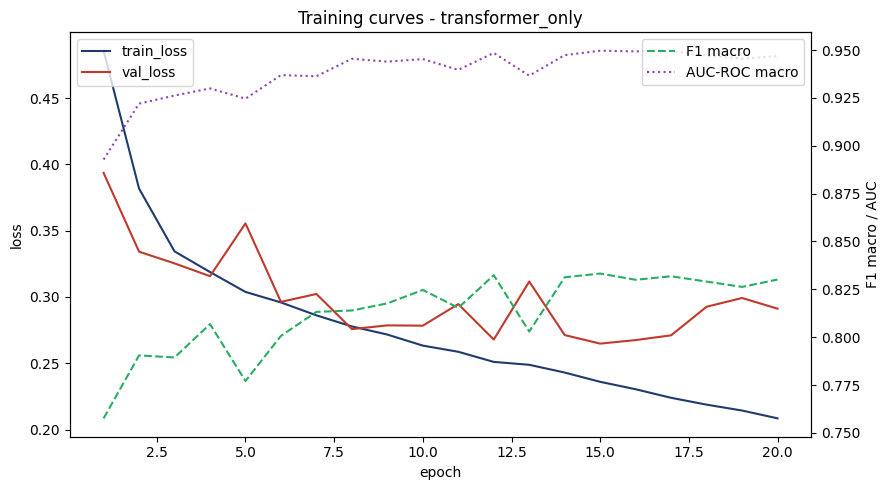

In [20]:
# Plot training and validation curves for the last seed executed.
x = range(1, len(history["train_loss"]) + 1)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(x, history["train_loss"], label="train_loss", color="#1f3b6e")
ax1.plot(x, history["val_loss"], label="val_loss", color="#c0392b")
ax1.set_xlabel("epoch")
ax1.set_ylabel("loss")
ax1.legend(loc="upper left")

# Display validation F1-macro and AUC-ROC on a secondary axis.
ax2 = ax1.twinx()
ax2.plot(x, history["val_f1_macro"], label="F1 macro", color="#27ae60", ls="--")
ax2.plot(x, history["val_auc_macro"], label="AUC-ROC macro", color="#8e44ad",
         ls=":")
ax2.set_ylabel("F1 macro / AUC")
ax2.legend(loc="upper right")

plt.title(f"Training curves - {ARCH_NAME}")
plt.tight_layout()
plt.show()